<a href="https://colab.research.google.com/github/navyaa377/EDA_House_Prices/blob/main/EDA_House_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory Data Analysis of the Ames Housing Dataset

**Dataset:** House Prices: Advanced Regression Techniques (Kaggle), `train.csv` (about 1,460 rows x 81 columns)
**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, SciPy, Jupyter Notebook
**Objective:** Use exploratory data analysis only (no machine learning) to understand which factors drive house sale prices, and to practise the full EDA workflow.

## Guiding questions (written before touching the data)
1. How is `SalePrice` distributed? Is it skewed?
2. Which numerical features correlate most strongly with `SalePrice`?
3. Does overall quality (`OverallQual`) change price in a clear, ordered way?
4. Do some neighborhoods consistently cost more than others?
5. Are there outliers, and are they errors or real but unusual sales?
6. Which columns have missing values, and which of those are not truly missing?

> Put `train.csv` (from Kaggle) in the same folder as this notebook before running.

## 2. Data loading (Step 1: Setup and first look)
**What I am about to do:** import the libraries, set a plotting style, load `train.csv`, and inspect shape, types and missing values.

In [8]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 12

df = pd.read_csv("/train.csv")
raw_df = df.copy()   # untouched backup

print("Shape:", df.shape)
display(df.head())
df.info()

missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
missing_table = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": (missing / len(df) * 100).round(2)
})
print("\nColumns with missing values:", len(missing_table))
display(missing_table)

Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

,missing_count,missing_pct
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageQual,81,5.55
GarageFinish,81,5.55
GarageType,81,5.55


**What I learned (Step 1 note):**
- Rows / columns: *(fill in from the output, expected 1460 x 81)*
- Number of columns with missing values: *(fill in)*
- First impressions: the columns with the most missing values (`PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`) are mostly "feature absent", not unknown. `LotFrontage` is the main genuinely missing numeric column.

## 3. Data understanding (Steps 2 and 3)
### Step 2: Classify variables
**What I am about to do:** split columns into numerical, categorical and ordinal groups, and build a summary table.

In [9]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()

# Ordinal quality scale: Po < Fa < TA < Gd < Ex
quality_order = ["Po", "Fa", "TA", "Gd", "Ex"]
ordinal_map = {
    "ExterQual": quality_order,
    "KitchenQual": quality_order,
}
for col, order in ordinal_map.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

def col_type(c):
    if c in ordinal_map or c == "OverallQual":
        return "ordinal"
    if c in numeric_cols:
        return "numerical (discrete)" if df[c].nunique() < 30 else "numerical (continuous)"
    return "categorical (nominal)"

summary = pd.DataFrame({
    "column": df.columns,
    "type": [col_type(c) for c in df.columns],
    "unique_values": [df[c].nunique() for c in df.columns],
    "examples": [list(df[c].dropna().unique()[:3]) for c in df.columns],
})
print("Numeric:", len(numeric_cols), "| Categorical (object):", len(categorical_cols))
print(summary["type"].value_counts())
display(summary)

Numeric: 38 | Categorical (object): 43
type
categorical (nominal)     41
numerical (continuous)    20
numerical (discrete)      17
ordinal                    3
Name: count, dtype: int64


,column,type,unique_values,examples
0,Id,numerical (continuous),1460,"[1, 2, 3]"
1,MSSubClass,numerical (discrete),15,"[60, 20, 70]"
2,MSZoning,categorical (nominal),5,"[RL, RM, C (all)]"
3,LotFrontage,numerical (continuous),110,"[65.0, 80.0, 68.0]"
4,LotArea,numerical (continuous),1073,"[8450, 9600, 11250]"
...,...,...,...,...
76,MoSold,numerical (discrete),12,"[2, 5, 9]"
77,YrSold,numerical (discrete),5,"[2008, 2007, 2006]"
78,SaleType,categorical (nominal),9,"[WD, New, COD]"
79,SaleCondition,categorical (nominal),6,"[Normal, Abnorml, Partial]"


**What I learned:** `OverallQual` is stored as a number (1 to 10) but is really **ordinal**: the gap between 4 and 5 is not guaranteed to equal the gap between 8 and 9. `ExterQual` and `KitchenQual` are now ordered categoricals.

### Step 3: Descriptive statistics
**What I am about to do:** compute centre and spread (mean, median, mode, std, variance, range, IQR, skewness, kurtosis) for `SalePrice`, `GrLivArea`, `LotArea`.

In [10]:
display(df[numeric_cols].describe().T)

rows = []
for c in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[c]
    mean, median = s.mean(), s.median()
    rows.append({
        "column": c,
        "mean": mean,
        "median": median,
        "mode": s.mode()[0],
        "std": s.std(),
        "variance": s.var(),
        "range": s.max() - s.min(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "skewness": stats.skew(s),
        "kurtosis": stats.kurtosis(s),
        "shape": "right skewed" if mean > median else ("left skewed" if mean < median else "symmetric"),
    })
stats_table = pd.DataFrame(rows).set_index("column")
display(stats_table.round(2))

for c in ["Neighborhood", "HouseStyle"]:
    print(f"\n{c}: mode = {df[c].mode()[0]}")
    display(df[c].value_counts().to_frame("count"))

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


,mean,median,mode,std,variance,range,IQR,skewness,kurtosis,shape
column,,,,,,,,,,
SalePrice,180921.20,163000.0,140000,79442.50,6.311111e+09,720100,84025.00,1.88,6.51,right skewed
GrLivArea,1515.46,1464.0,864,525.48,2.761296e+05,5308,647.25,1.37,4.87,right skewed
LotArea,10516.83,9478.5,7200,9981.26,9.962565e+07,213945,4048.00,12.20,202.54,right skewed



Neighborhood: mode = NAmes


,count
Neighborhood,
NAmes,225
CollgCr,150
OldTown,113
Edwards,100
Somerst,86
Gilbert,79
NridgHt,77
Sawyer,74
NWAmes,73



HouseStyle: mode = 1Story


,count
HouseStyle,
1Story,726
2Story,445
1.5Fin,154
SLvl,65
SFoyer,37
1.5Unf,14
2.5Unf,11
2.5Fin,8


**Interpretation:** The mean of `SalePrice` is above its median, so a small number of expensive houses pull the mean upward: the distribution is **right skewed**. The median is the safer "typical price". `GrLivArea` and `LotArea` also show positive skew; `LotArea` has very high kurtosis (extreme lot sizes).

## 4. Data cleaning (Step 9, run early because it affects later steps)
**What I am about to do:** remove duplicates, check categorical labels, treat "NA means feature absent" columns, fill genuine missing numeric values, and check for impossible values. Each decision is documented.

In [11]:
# 1. Duplicates (ignore Id, which is always unique)
dup_count = df.drop(columns="Id").duplicated().sum()
print("Duplicate rows:", dup_count)
if dup_count > 0:
    df = df.drop_duplicates(subset=df.columns.drop("Id"))
    print("New shape:", df.shape)

# 2. Inconsistent labels (casing, extra spaces)
problems = {}
for c in categorical_cols:
    vals = df[c].dropna().astype(str)
    stripped = vals.str.strip()
    n_space = (vals != stripped).sum()
    n_case = stripped.nunique() - stripped.str.lower().nunique()
    if n_space or n_case:
        problems[c] = {"extra_spaces": int(n_space), "case_variants": int(n_case)}
print("Columns with label problems:", problems if problems else "none found")
for c in problems:
    df[c] = df[c].astype(str).str.strip()   # keep original casing so ordinal codes still work

Duplicate rows: 0
Columns with label problems: none found


In [12]:
# 3. "NA" really means "this feature does not exist" in these columns -> fill with "None"
none_means_absent = [
    "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
    "GarageType", "GarageFinish", "GarageQual", "GarageCond",
    "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
    "MasVnrType",
]
for c in none_means_absent:
    df[c] = df[c].fillna("None")

# 4. Numeric columns with missing values
# LotFrontage: genuinely missing -> median of the same Neighborhood (similar lots are similar)
df["LotFrontage"] = df.groupby("Neighborhood")["LotFrontage"].transform(lambda s: s.fillna(s.median()))
df["LotFrontage"] = df["LotFrontage"].fillna(df["LotFrontage"].median())
# MasVnrArea: missing means no veneer -> 0
df["MasVnrArea"] = df["MasVnrArea"].fillna(0)
# GarageYrBlt: missing means no garage; use YearBuilt as a neutral stand-in (0 would distort correlations)
df["GarageYrBlt"] = df["GarageYrBlt"].fillna(df["YearBuilt"])
# Electrical: a single genuinely missing label -> mode
df["Electrical"] = df["Electrical"].fillna(df["Electrical"].mode()[0])

print("Remaining missing values:", int(df.isnull().sum().sum()))

# 5. Impossible values
print("YearBuilt > YrSold      :", int((df["YearBuilt"] > df["YrSold"]).sum()))
print("YearRemodAdd < YearBuilt:", int((df["YearRemodAdd"] < df["YearBuilt"]).sum()))
area_cols = [c for c in df.columns if "SF" in c or "Area" in c]
print("Negative areas          :", int((df[area_cols] < 0).any(axis=1).sum()))

Remaining missing values: 0
YearBuilt > YrSold      : 0
YearRemodAdd < YearBuilt: 0
Negative areas          : 0


**What I learned / decisions made:**
- Duplicates: *(fill in, expected 0)*.
- Many "missing" values were really **feature absent** (no pool, no alley, no fence, no garage, no basement). Dropping these columns or rows would have thrown away real information.
- `LotFrontage` filled with neighborhood median; `MasVnrArea` with 0; `GarageYrBlt` with `YearBuilt`; `Electrical` with its mode.
- No impossible values expected (check the printed counts).

## 5. Univariate analysis (Step 4: Distributions)
**What I am about to do:** look at the shape of `SalePrice` (histogram + KDE, boxplot, log histogram), then price by quality and neighborhood, plus category counts.

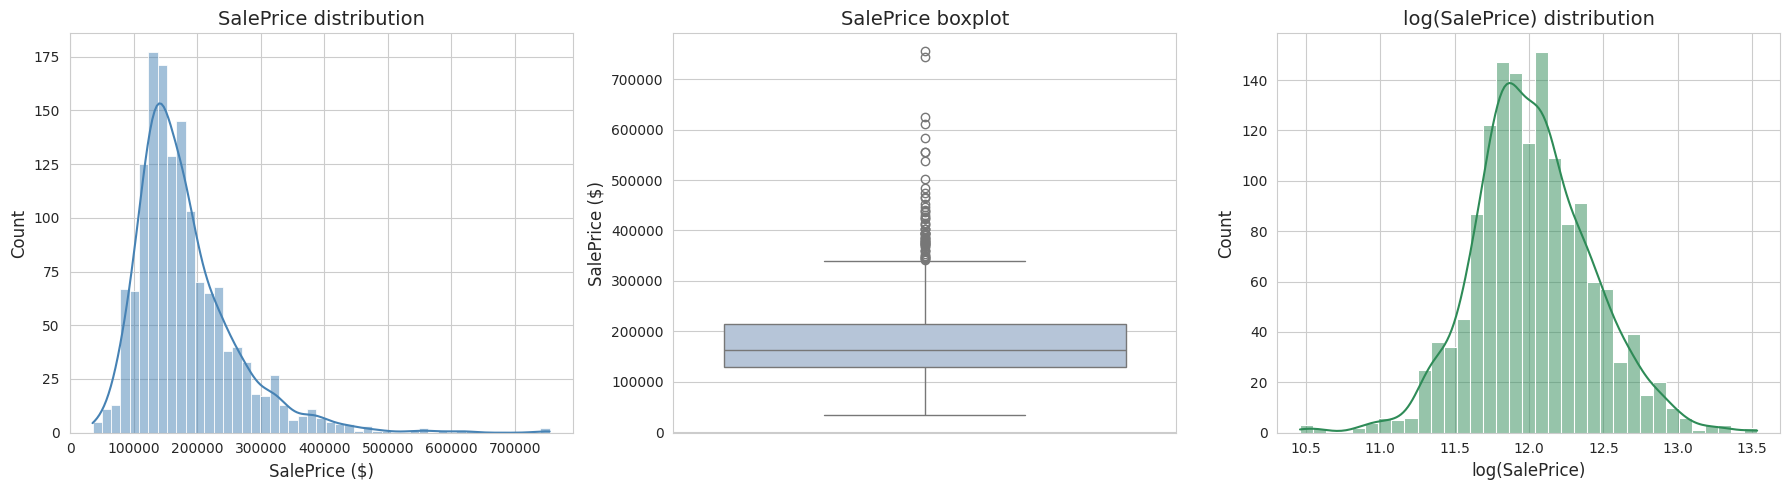

Skewness before log: 1.881
Skewness after  log: 0.121


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="steelblue")
axes[0].set(title="SalePrice distribution", xlabel="SalePrice ($)", ylabel="Count")

sns.boxplot(y=df["SalePrice"], ax=axes[1], color="lightsteelblue")
axes[1].set(title="SalePrice boxplot", ylabel="SalePrice ($)")

sns.histplot(np.log(df["SalePrice"]), kde=True, ax=axes[2], color="seagreen")
axes[2].set(title="log(SalePrice) distribution", xlabel="log(SalePrice)", ylabel="Count")

plt.tight_layout()
plt.show()

print("Skewness before log:", round(stats.skew(df["SalePrice"]), 3))
print("Skewness after  log:", round(stats.skew(np.log(df["SalePrice"])), 3))

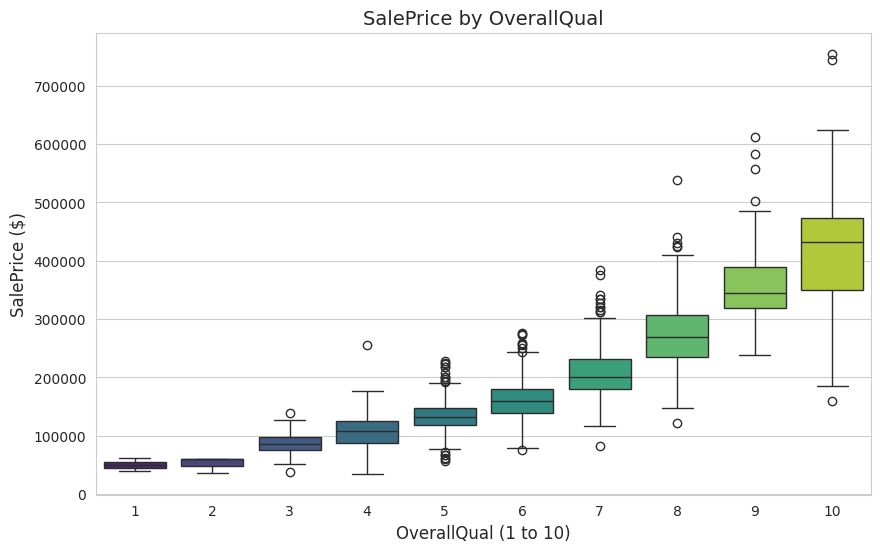

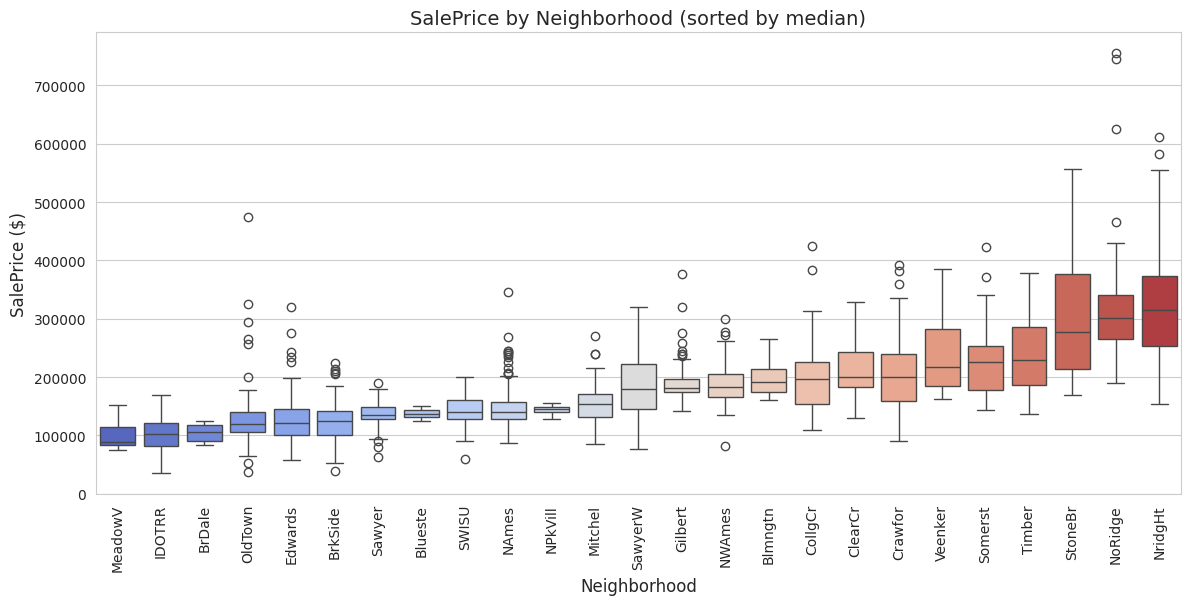

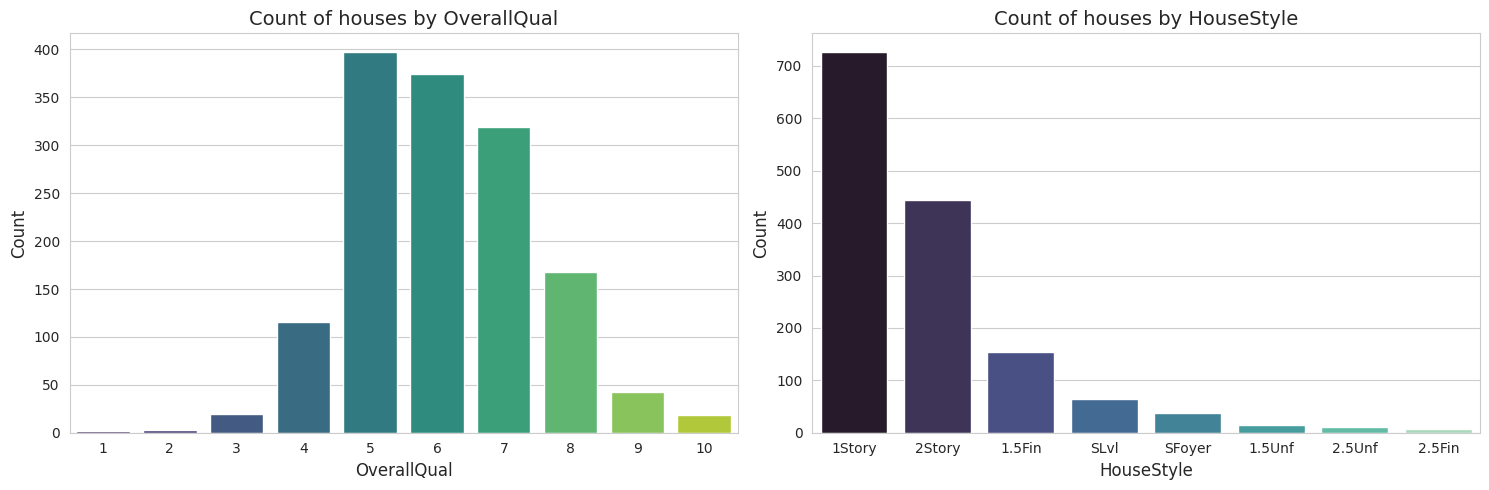

In [14]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", palette="viridis")
plt.title("SalePrice by OverallQual")
plt.xlabel("OverallQual (1 to 10)")
plt.ylabel("SalePrice ($)")
plt.show()

order = df.groupby("Neighborhood")["SalePrice"].median().sort_values().index
plt.figure(figsize=(14, 6))
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=order, palette="coolwarm")
plt.xticks(rotation=90)
plt.title("SalePrice by Neighborhood (sorted by median)")
plt.xlabel("Neighborhood")
plt.ylabel("SalePrice ($)")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(data=df, x="OverallQual", ax=axes[0], palette="viridis")
axes[0].set(title="Count of houses by OverallQual", xlabel="OverallQual", ylabel="Count")
sns.countplot(data=df, x="HouseStyle", ax=axes[1], palette="mako",
              order=df["HouseStyle"].value_counts().index)
axes[1].set(title="Count of houses by HouseStyle", xlabel="HouseStyle", ylabel="Count")
plt.tight_layout()
plt.show()

**What I learned:** `SalePrice` is right skewed with a long upper tail of expensive homes. The log transform pulls the skewness close to zero, so the log-price is close to normal. Median price rises steadily with `OverallQual`, with wider spread at the top. A few neighborhoods (for example NoRidge, NridgHt, StoneBr) have clearly higher medians. Most houses sit in the middle quality range (5 to 7).

## 6. Bivariate and multivariate analysis (Steps 5, 6, 7)
### Step 5: Correlation and covariance
**What I am about to do:** compute covariance and Pearson correlation for numeric columns and rank features by correlation with `SalePrice`.

In [15]:
num_df = df[numeric_cols].drop(columns="Id")

cov_matrix = num_df.cov()
corr_matrix = num_df.corr(method="pearson")

top_corr = corr_matrix["SalePrice"].abs().sort_values(ascending=False)
top10_features = top_corr.index[1:11].tolist()    # skip SalePrice itself
print("Top 10 features by |correlation| with SalePrice:")
display(corr_matrix.loc[top10_features, "SalePrice"].to_frame("pearson_r"))

print("\nTop 3 features: covariance vs correlation with SalePrice")
for f in top10_features[:3]:
    print(f"{f:12s} cov = {cov_matrix.loc[f, 'SalePrice']:>16,.1f}   corr = {corr_matrix.loc[f, 'SalePrice']:.3f}")

# Optional: Spearman for ordinal columns
ord_df = pd.DataFrame({
    "OverallQual": df["OverallQual"],
    "ExterQual": df["ExterQual"].cat.codes,
    "KitchenQual": df["KitchenQual"].cat.codes,
    "SalePrice": df["SalePrice"],
})
print("\nSpearman correlation with SalePrice (ordinal columns):")
display(ord_df.corr(method="spearman")["SalePrice"].drop("SalePrice").to_frame("spearman_rho"))

print("\nGarageArea vs GarageCars correlation:",
      round(df["GarageArea"].corr(df["GarageCars"]), 3))

Top 10 features by |correlation| with SalePrice:


,pearson_r
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
GarageYrBlt,0.508043



Top 3 features: covariance vs correlation with SalePrice
OverallQual  cov =         86,904.1   corr = 0.791
GrLivArea    cov =     29,581,866.7   corr = 0.709
GarageCars   cov =         38,020.2   corr = 0.640

Spearman correlation with SalePrice (ordinal columns):


,spearman_rho
OverallQual,0.809829
ExterQual,0.684014
KitchenQual,0.672849



GarageArea vs GarageCars correlation: 0.882


**Interpretation:**
- Covariance depends on the units of both variables (for example square feet times dollars), so values cannot be compared across features. Correlation is scaled to -1 to +1, so it can be.
- Correlation is not causation. `GarageArea` and `GarageCars` are strongly correlated with each other (multicollinearity): they carry almost the same information, so both appearing in a top-10 list does not mean two independent effects on price.
- `OverallQual` and `GrLivArea` should be at or near the top.

### Step 6: Scatter plots and pair plots
**What I am about to do:** visualise `GrLivArea`, `TotalBsmtSF`, `YearBuilt` against price, flag unusual large cheap houses, and draw a pair plot.

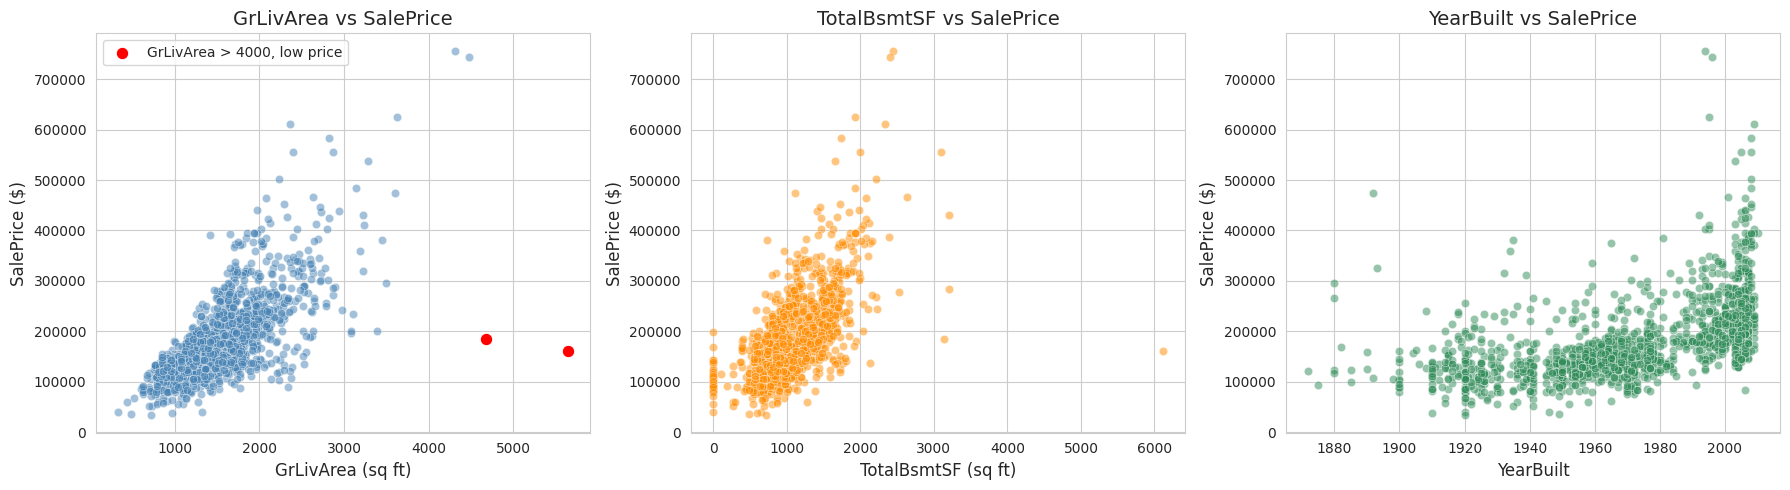

Unusual large-but-cheap houses: 2


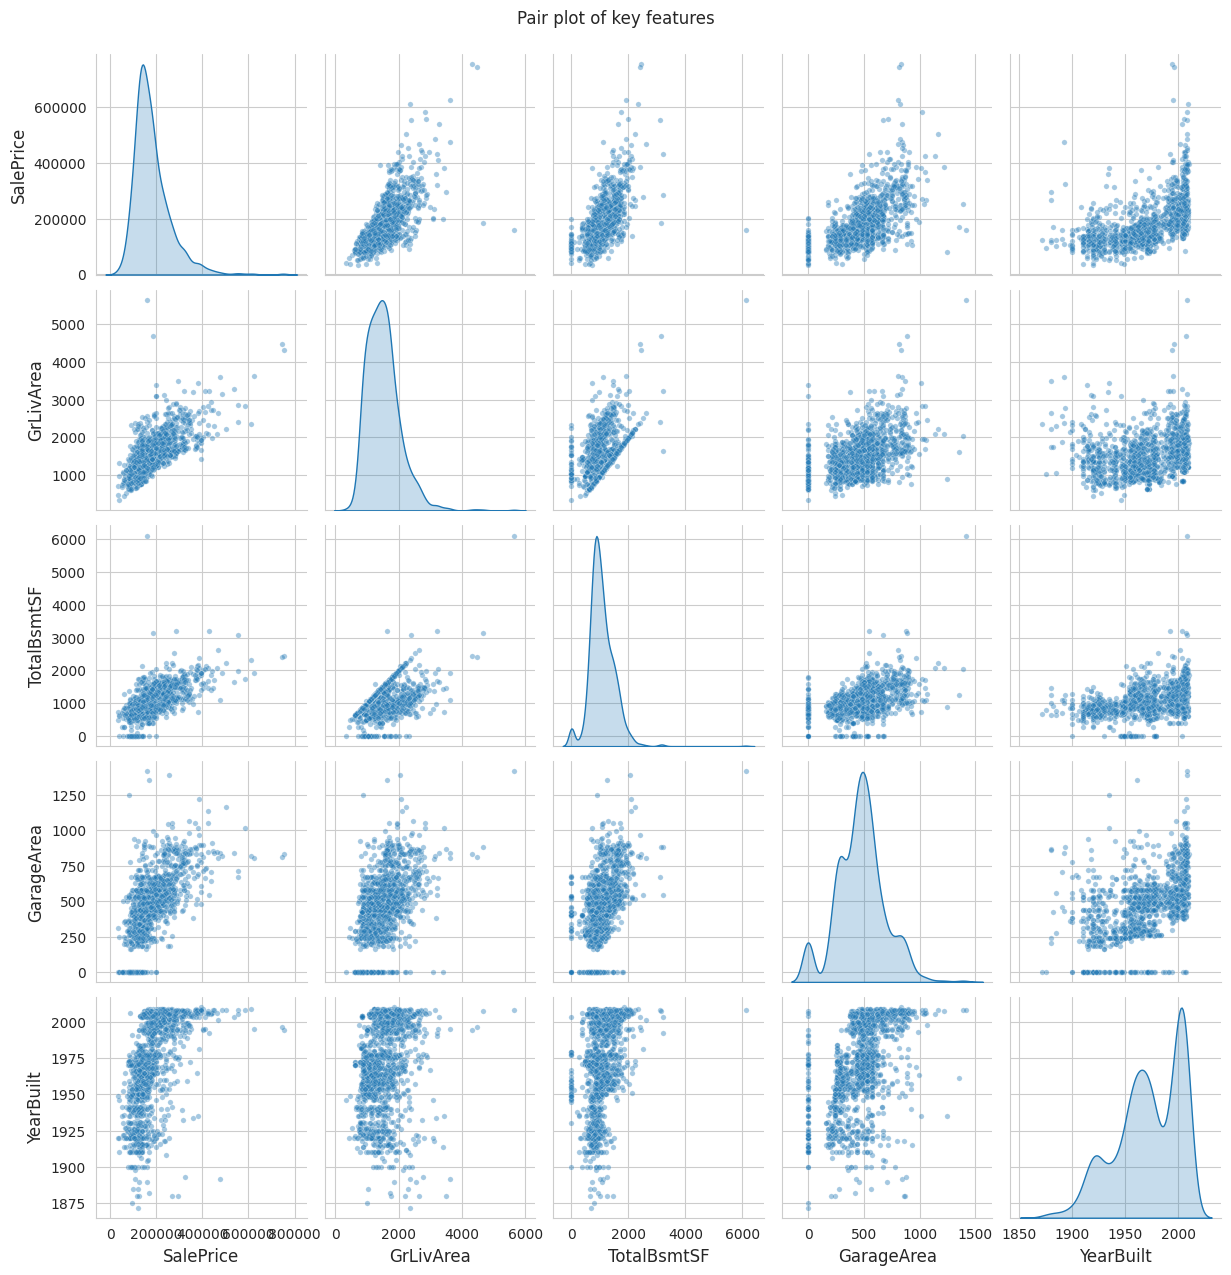

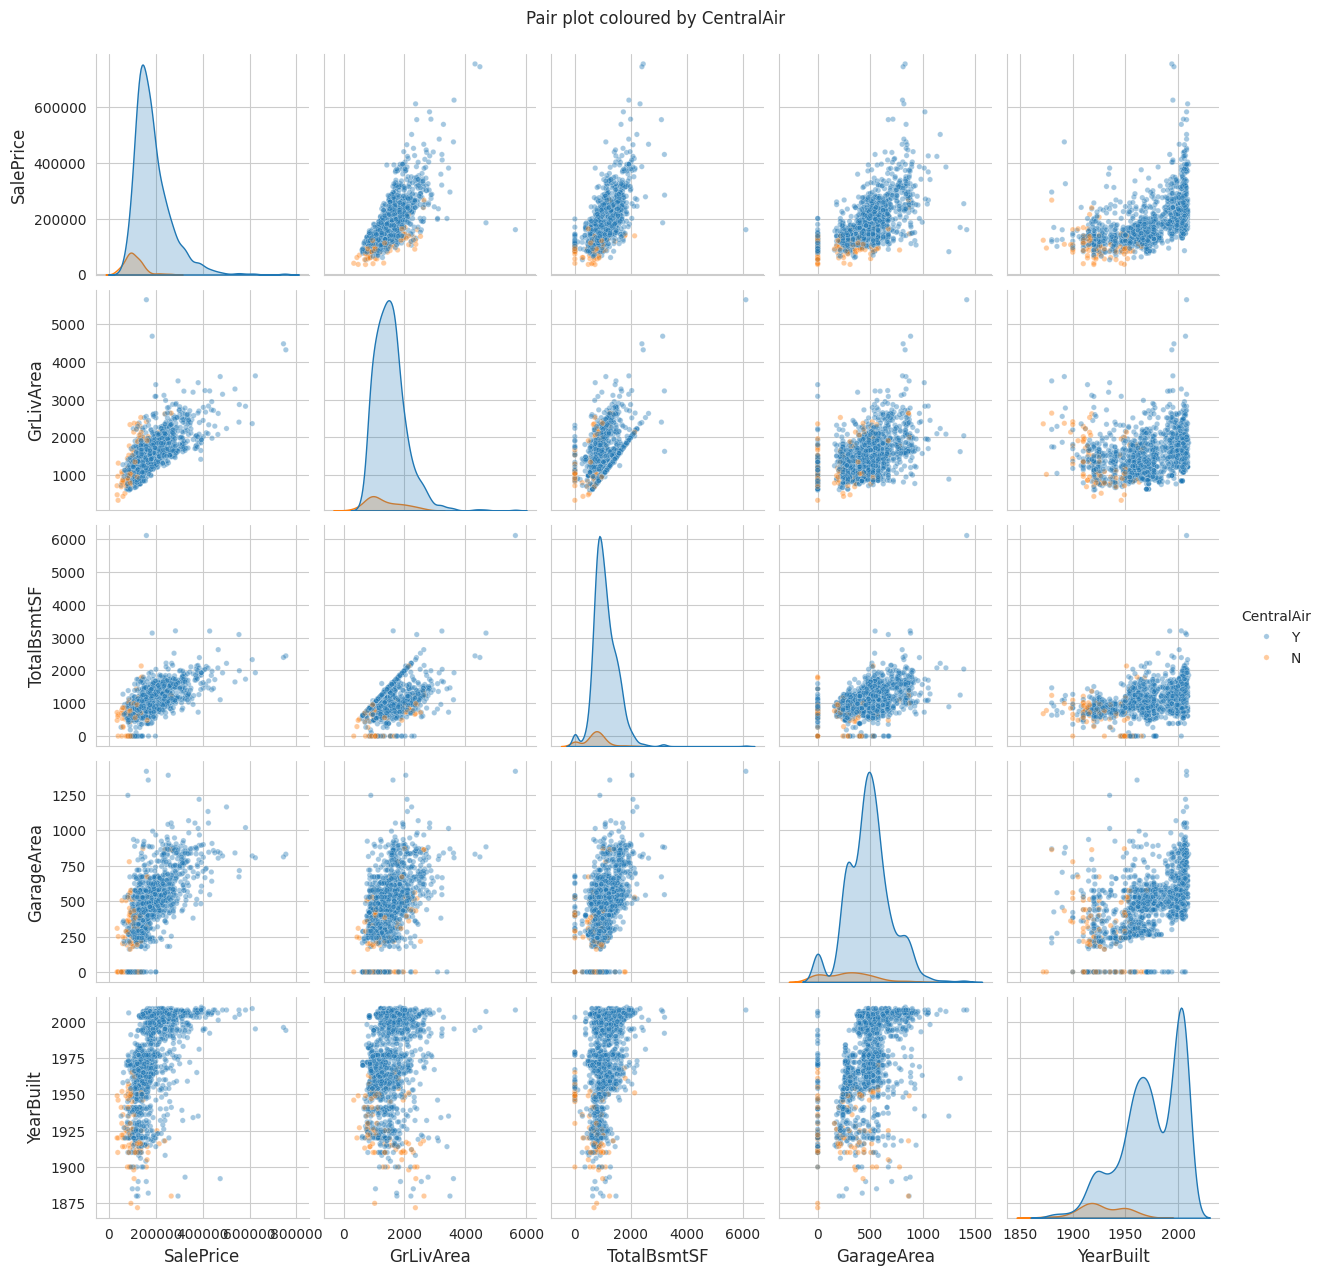

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

unusual = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)
sns.scatterplot(data=df[~unusual], x="GrLivArea", y="SalePrice", alpha=0.5, ax=axes[0], color="steelblue")
sns.scatterplot(data=df[unusual], x="GrLivArea", y="SalePrice", color="red", s=80, ax=axes[0],
                label="GrLivArea > 4000, low price")
axes[0].set(title="GrLivArea vs SalePrice", xlabel="GrLivArea (sq ft)", ylabel="SalePrice ($)")

sns.scatterplot(data=df, x="TotalBsmtSF", y="SalePrice", alpha=0.5, ax=axes[1], color="darkorange")
axes[1].set(title="TotalBsmtSF vs SalePrice", xlabel="TotalBsmtSF (sq ft)", ylabel="SalePrice ($)")

sns.scatterplot(data=df, x="YearBuilt", y="SalePrice", alpha=0.5, ax=axes[2], color="seagreen")
axes[2].set(title="YearBuilt vs SalePrice", xlabel="YearBuilt", ylabel="SalePrice ($)")

plt.tight_layout()
plt.show()
print("Unusual large-but-cheap houses:", int(unusual.sum()))

selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
g = sns.pairplot(df[selected], diag_kind="kde", plot_kws={"alpha": 0.4, "s": 15})
g.fig.suptitle("Pair plot of key features", y=1.02)
plt.show()

g = sns.pairplot(df[selected + ["CentralAir"]], hue="CentralAir", diag_kind="kde",
                 plot_kws={"alpha": 0.4, "s": 15})
g.fig.suptitle("Pair plot coloured by CentralAir", y=1.02)
plt.show()

**What I learned:** price rises roughly linearly with `GrLivArea` and `TotalBsmtSF`, and newer houses tend to cost more. A few very large houses (`GrLivArea` > 4000) sold for low prices and break the trend.

### Step 7: Correlation heatmap
**What I am about to do:** show one clear heatmap of the 10 features most correlated with `SalePrice` (plus `SalePrice` itself), hiding the duplicate upper half.

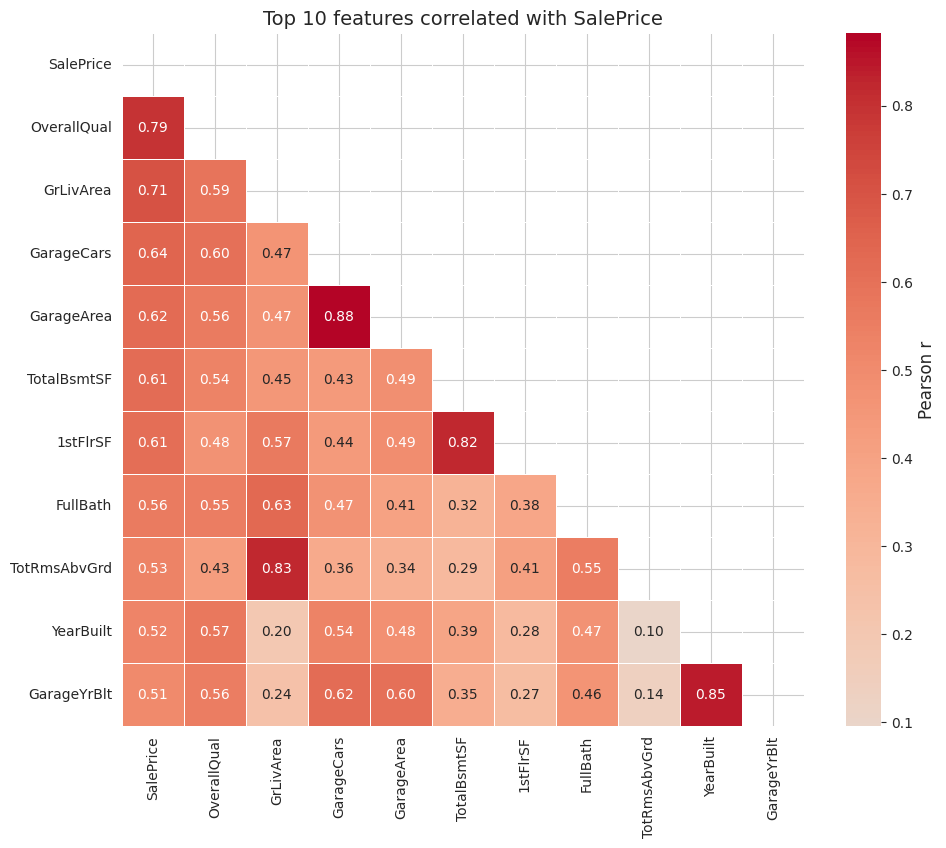

In [17]:
cols = ["SalePrice"] + top10_features
corr_top = df[cols].corr()
mask = np.triu(np.ones_like(corr_top, dtype=bool))

plt.figure(figsize=(11, 9))
sns.heatmap(corr_top, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, cbar_kws={"label": "Pearson r"})
plt.title("Top 10 features correlated with SalePrice")
plt.show()

**What I learned:** several top features are correlated with each other too (for example `GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`, `GrLivArea`/`TotRmsAbvGrd`), which matters if these were ever used together in a model.

## 7. Outlier analysis (Step 8)
**What I am about to do:** detect outliers in `GrLivArea` and `SalePrice` with the IQR rule and the z-score rule, compare them, and decide what to remove.

GrLivArea: IQR flags 31, z-score flags 16, overlap 16


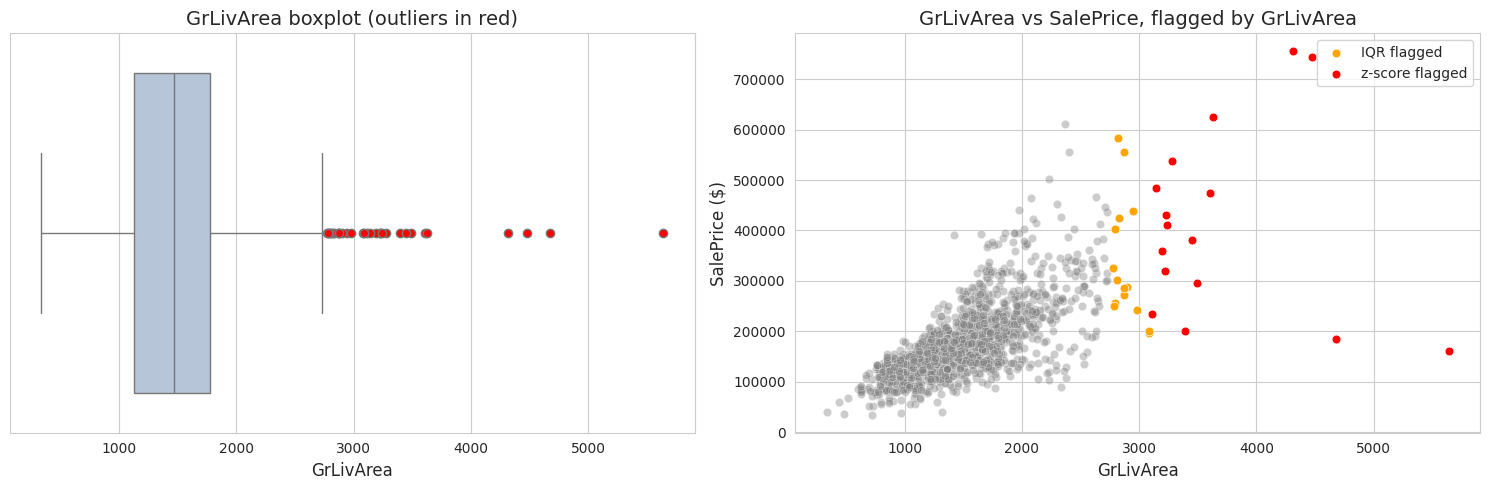

SalePrice: IQR flags 61, z-score flags 22, overlap 22


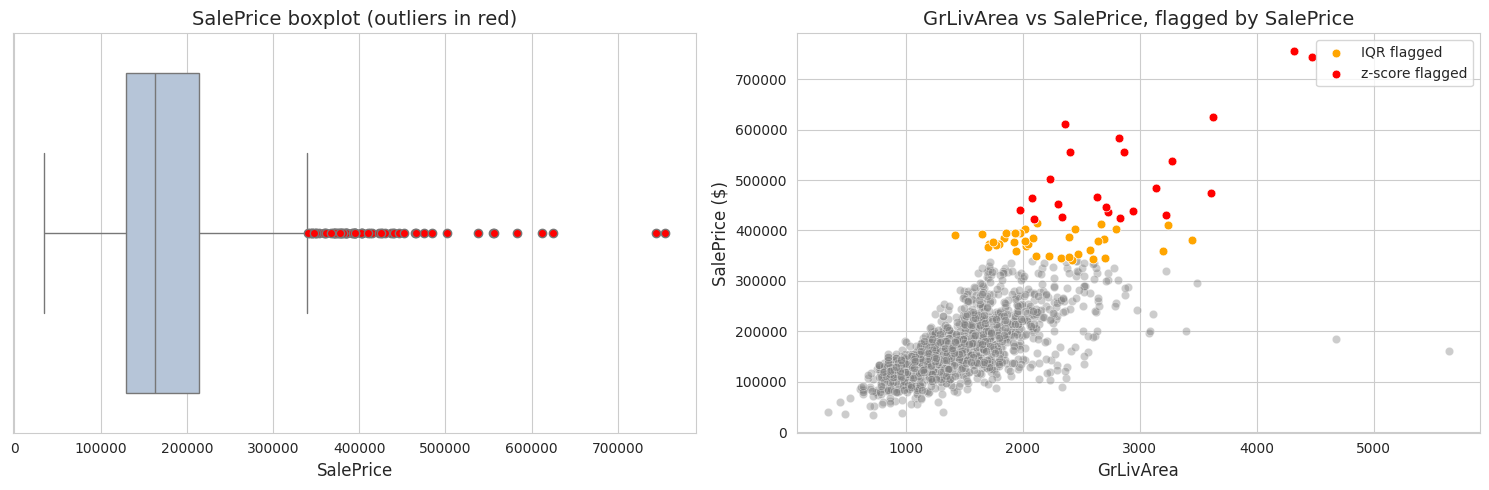

In [18]:
def iqr_outliers(series):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return series[(series < lower) | (series > upper)]

def zscore_outliers(series, threshold=3):
    z = (series - series.mean()) / series.std()
    return series[np.abs(z) > threshold]

for col in ["GrLivArea", "SalePrice"]:
    a = iqr_outliers(df[col])
    b = zscore_outliers(df[col])
    overlap = a.index.intersection(b.index)
    print(f"{col}: IQR flags {len(a)}, z-score flags {len(b)}, overlap {len(overlap)}")

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    sns.boxplot(x=df[col], ax=axes[0], color="lightsteelblue", flierprops={"markerfacecolor": "red"})
    axes[0].set(title=f"{col} boxplot (outliers in red)", xlabel=col)

    sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", alpha=0.4, ax=axes[1], color="grey")
    sns.scatterplot(x=df.loc[a.index, "GrLivArea"], y=df.loc[a.index, "SalePrice"],
                    color="orange", s=40, ax=axes[1], label="IQR flagged")
    sns.scatterplot(x=df.loc[b.index, "GrLivArea"], y=df.loc[b.index, "SalePrice"],
                    color="red", s=40, ax=axes[1], label="z-score flagged")
    axes[1].set(title=f"GrLivArea vs SalePrice, flagged by {col}", xlabel="GrLivArea", ylabel="SalePrice ($)")
    plt.tight_layout()
    plt.show()

In [19]:
# Decision: very large houses with very low prices look like non-typical sales
# (partial sales / unfinished houses) and distort the trend line -> remove them.
# Expensive but sensible houses (large AND expensive) are real sales -> keep.
bad = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 300000)
print("Rows removed:", int(bad.sum()))
print(df.loc[bad, ["Id", "GrLivArea", "SalePrice", "SaleCondition", "Neighborhood"]])

df_clean = df[~bad].copy()
print("Shape before / after:", df.shape, df_clean.shape)

r_before = df["GrLivArea"].corr(df["SalePrice"])
r_after = df_clean["GrLivArea"].corr(df_clean["SalePrice"])
print(f"GrLivArea-SalePrice correlation: before {r_before:.3f}, after {r_after:.3f}")

Rows removed: 2
        Id  GrLivArea  SalePrice SaleCondition Neighborhood
523    524       4676     184750       Partial      Edwards
1298  1299       5642     160000       Partial      Edwards
Shape before / after: (1460, 81) (1458, 81)
GrLivArea-SalePrice correlation: before 0.709, after 0.735


**Interpretation:** the z-score method flags fewer points on a skewed variable because the outliers themselves inflate the mean and standard deviation, which shrinks the z-scores of everything else. The IQR rule uses quartiles, which are robust to extreme values, so it flags more points in the long tail.

**Decision:** removed the handful of very large, very cheap houses (likely partial / unusual sales; check `SaleCondition`). Other high-priced houses are genuine and were kept. Removal strengthens the `GrLivArea`-`SalePrice` correlation.

## 8. Dashboard (Step 10: Final dashboard and storytelling)
**What I am about to do:** combine four of the best visuals into one figure with a consistent palette and save it as `eda_dashboard.png`.

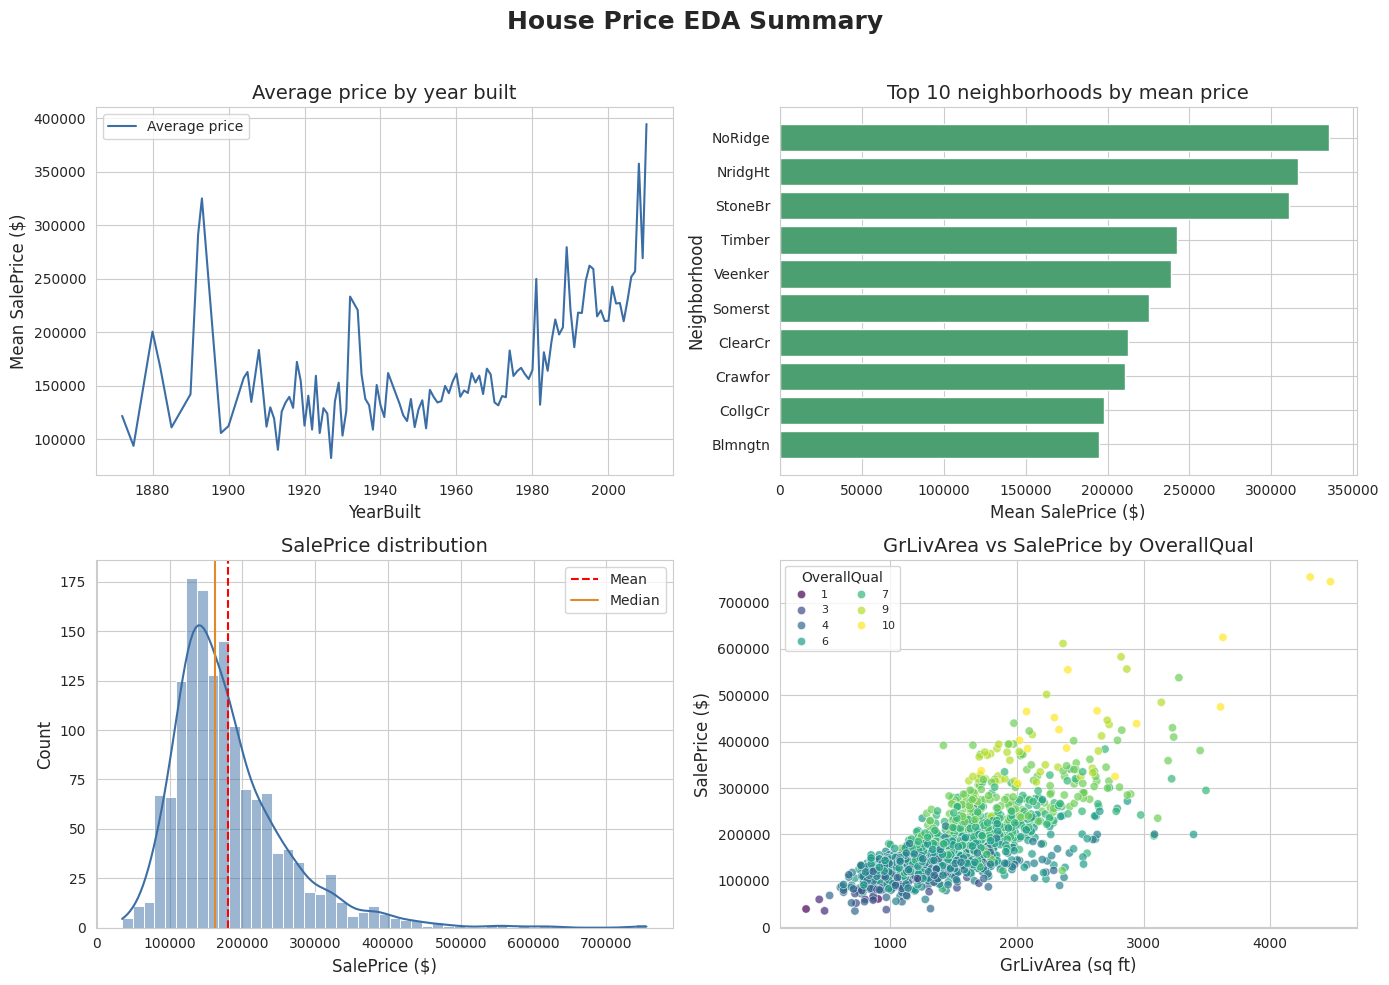

In [20]:
blue, green, orange = "#3b6ea5", "#4c9f70", "#e08a2c"

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: line plot, average price by year built
avg_by_year = df_clean.groupby("YearBuilt")["SalePrice"].mean()
axes[0, 0].plot(avg_by_year.index, avg_by_year.values, color=blue, label="Average price")
axes[0, 0].set(title="Average price by year built", xlabel="YearBuilt", ylabel="Mean SalePrice ($)")
axes[0, 0].legend()

# Panel 2: horizontal bar, top 10 neighborhoods by mean price
top_nb = df_clean.groupby("Neighborhood")["SalePrice"].mean().sort_values().tail(10)
axes[0, 1].barh(top_nb.index, top_nb.values, color=green)
axes[0, 1].set(title="Top 10 neighborhoods by mean price", xlabel="Mean SalePrice ($)", ylabel="Neighborhood")

# Panel 3: histogram + KDE with mean and median lines
sns.histplot(df_clean["SalePrice"], kde=True, color=blue, ax=axes[1, 0])
axes[1, 0].axvline(df_clean["SalePrice"].mean(), color="red", linestyle="--", label="Mean")
axes[1, 0].axvline(df_clean["SalePrice"].median(), color=orange, linestyle="-", label="Median")
axes[1, 0].set(title="SalePrice distribution", xlabel="SalePrice ($)", ylabel="Count")
axes[1, 0].legend()

# Panel 4: scatter coloured by OverallQual
sc = sns.scatterplot(data=df_clean, x="GrLivArea", y="SalePrice", hue="OverallQual",
                     palette="viridis", alpha=0.7, ax=axes[1, 1])
axes[1, 1].set(title="GrLivArea vs SalePrice by OverallQual", xlabel="GrLivArea (sq ft)", ylabel="SalePrice ($)")
axes[1, 1].legend(title="OverallQual", fontsize=8, ncol=2)

fig.suptitle("House Price EDA Summary", fontsize=18, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig("eda_dashboard.png", dpi=150)
plt.show()

**What I learned:** newer homes, certain neighborhoods, higher quality and larger living area all go with higher prices; the mean sits above the median because of the right-skewed tail.

## 9. Conclusions
### Verifying the expected insights

In [21]:
print("1. Skewness SalePrice: %.2f -> log: %.2f" % (stats.skew(df["SalePrice"]), stats.skew(np.log(df["SalePrice"]))))
print("2. Top correlates:", top10_features[:3])
print("3. Median price by OverallQual:")
print(df.groupby("OverallQual")["SalePrice"].median().astype(int).to_string())
print("4. Top 5 / bottom 3 neighborhoods by median price:")
nb_med = df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False).astype(int)
print(nb_med.head(5).to_string()); print("..."); print(nb_med.tail(3).to_string())
print("5. Unusual large-cheap sales removed:", int(bad.sum()))
print("6. Columns where NA meant 'feature absent':", len(none_means_absent))

1. Skewness SalePrice: 1.88 -> log: 0.12
2. Top correlates: ['OverallQual', 'GrLivArea', 'GarageCars']
3. Median price by OverallQual:
OverallQual
1      50150
2      60000
3      86250
4     108000
5     133000
6     160000
7     200141
8     269750
9     345000
10    432390
4. Top 5 / bottom 3 neighborhoods by median price:
Neighborhood
NridgHt    315000
NoRidge    301500
StoneBr    278000
Timber     228475
Somerst    225500
...
Neighborhood
BrDale     106000
IDOTRR     103000
MeadowV     88000
5. Unusual large-cheap sales removed: 2
6. Columns where NA meant 'feature absent': 15


### Answers to the guiding questions
1. **Distribution:** `SalePrice` is right skewed (mean > median); a log transform makes it close to normal.
2. **Correlates:** `OverallQual` and `GrLivArea` are among the strongest, followed by garage and basement size.
3. **Quality:** price rises steadily and in order with `OverallQual`, with larger spread at the top.
4. **Neighborhoods:** a few neighborhoods have clearly higher medians than the rest.
5. **Outliers:** a handful of very large, very cheap houses are unusual sales that distort the trend line; they were removed. High-priced but consistent houses were kept.
6. **Missing values:** many apparent gaps (`PoolQC`, `Alley`, `Fence`, `FireplaceQu`, garage and basement columns) mean the feature is absent and were filled with "None", not dropped. `LotFrontage` was the main truly missing column.

### Limitations
- One city and a limited time window, so results may not generalise.
- Correlation is not causation; many features are correlated with each other.
- Imputation choices (neighborhood median for `LotFrontage`, `YearBuilt` for `GarageYrBlt`) are assumptions.
- No predictive modelling was done; this analysis only describes patterns.